In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

from utils import data_handling, k_folds

/Users/salimelouahdani/anaconda3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Data Import and Treatment

Importing Data

In [3]:
X = pd.read_csv('data/X_train.csv',index_col='ROW_ID')
Y = pd.read_csv('data/y_train.csv',index_col='ROW_ID')

Adding features

In [4]:
data_handling.add_features(X)

,TS,ALLOCATION,RET_20,RET_19,RET_18,RET_17,RET_16,RET_15,RET_14,RET_13,...,Vol_Momentum_5,Vol_Momentum_20,Vol_Ret_Confirm_1,Vol_Ret_Confirm_5,Signed_Vol_Ratio_5_20,Ret_vs_Group_5,Rank_in_Group_5,Ret_vs_Group_20,Rank_in_Group_20,Vol_vs_Group
ROW_ID,,,,,,,,,,,,,,,,,,,,,
0,DATE_0001,ALLOCATION_01,-0.018192,-0.000306,-0.006881,-0.002393,0.000507,-0.001270,-0.002539,0.002830,...,0.086381,0.613302,NaN,-0.000048,0.140846,0.000512,0.671429,-0.000986,0.100000,0.002844
1,DATE_0001,ALLOCATION_02,-0.006394,-0.001059,0.001565,0.000033,0.002829,0.001725,0.000875,-0.002160,...,-0.794794,-1.801508,NaN,-0.000243,-0.441183,0.000274,0.681818,0.000263,0.727273,0.000615
2,DATE_0001,ALLOCATION_03,-0.016587,-0.004517,-0.005306,0.004314,0.006471,-0.005868,-0.005030,-0.001488,...,0.736525,0.868016,NaN,-0.001467,0.848515,-0.000925,0.228571,-0.001170,0.042857,0.002773
3,DATE_0001,ALLOCATION_04,-0.005344,0.002790,0.006937,-0.004246,-0.005051,-0.000330,-0.000117,-0.005209,...,-0.929260,-0.822900,NaN,0.001590,-1.129251,-0.001496,0.085714,-0.001096,0.057143,0.001469
4,DATE_0001,ALLOCATION_05,-0.010506,-0.005491,0.007752,-0.012299,0.002191,0.003282,0.000495,-0.003489,...,1.278511,0.541321,NaN,-0.001475,2.361838,-0.001185,0.060606,0.000067,0.560606,0.003639
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
527068,DATE_2522,ALLOCATION_95,-0.000550,0.001751,0.002035,0.005264,0.003387,0.001825,-0.003642,0.001439,...,0.773799,1.015864,NaN,-0.000249,0.761716,-0.000583,0.196970,0.000591,0.863636,0.000518
527069,DATE_2522,ALLOCATION_96,0.003501,-0.004601,-0.001739,-0.000052,0.003670,0.002518,0.006307,0.001633,...,1.244381,0.877332,NaN,0.001047,1.418369,0.000741,0.785714,0.000371,0.814286,0.001035
527070,DATE_2522,ALLOCATION_97,0.005201,0.000580,-0.001607,-0.002955,0.000450,0.004747,0.004622,0.001928,...,1.311624,1.034578,NaN,0.000156,1.267786,0.000019,0.485714,0.000125,0.642857,0.000691


,RET_1,RET_2,RET_3,RET_4,RET_5,RET_6,RET_7,RET_8,RET_9,RET_10,RET_11,RET_12,RET_13,RET_14,RET_15,RET_16,RET_17,RET_18,RET_19,RET_20
RET_1,1.000000,0.105890,-0.079649,0.015452,-0.022430,-0.042606,0.002952,0.070668,0.063979,-0.035732,-0.040296,-0.031821,-0.017971,-0.056063,0.012367,0.018518,0.006266,0.049270,-0.009355,-0.036225
RET_2,0.105890,1.000000,0.066630,0.000268,0.002316,-0.016943,0.036481,0.018338,-0.066795,0.044306,0.046947,-0.002302,-0.045194,-0.029571,-0.046130,0.059396,0.018483,0.018203,-0.047536,-0.059699
RET_3,-0.079649,0.066630,1.000000,0.135711,-0.083891,-0.045387,-0.011805,-0.023460,-0.031980,-0.000794,0.030559,0.003664,-0.040547,0.033269,0.030048,0.019674,-0.023715,0.015675,0.022475,-0.073621
RET_4,0.015452,0.000268,0.135711,1.000000,0.009229,-0.122784,-0.014315,-0.002174,0.012404,0.002997,-0.010517,0.055434,0.046725,-0.071869,-0.044466,0.006478,-0.064835,0.046869,0.056304,-0.030736
RET_5,-0.022430,0.002316,-0.083891,0.009229,1.000000,0.156052,0.034175,-0.017025,-0.004269,-0.073558,-0.033202,0.030484,0.038248,-0.006723,-0.039585,-0.075727,-0.009461,0.062283,-0.024468,0.071666
RET_6,-0.042606,-0.016943,-0.045387,-0.122784,0.156052,1.000000,0.037488,-0.041808,-0.053689,-0.021235,-0.047083,-0.039674,-0.040179,0.061226,0.072934,-0.040773,0.045972,-0.010218,0.007031,0.040748
RET_7,0.002952,0.036481,-0.011805,-0.014315,0.034175,0.037488,1.000000,0.063059,-0.046199,0.065759,-0.046206,0.125023,0.061551,0.006570,-0.022627,0.047751,-0.065246,-0.027629,0.016104,-0.008515
RET_8,0.070668,0.018338,-0.023460,-0.002174,-0.017025,-0.041808,0.063059,1.000000,0.134776,0.031958,-0.054559,0.038316,-0.009007,0.005481,-0.018701,-0.017465,0.068385,-0.066375,-0.041500,-0.006216
RET_9,0.063979,-0.066795,-0.031980,0.012404,-0.004269,-0.053689,-0.046199,0.134776,1.000000,0.020006,-0.114079,-0.000892,0.057915,0.048035,0.027215,0.025665,0.061902,0.098205,-0.025100,-0.025291
RET_10,-0.035732,0.044306,-0.000794,0.002997,-0.073558,-0.021235,0.065759,0.031958,0.020006,1.000000,0.087939,0.017870,-0.033060,-0.042473,0.008647,0.043078,0.033620,-0.009042,0.051956,-0.044661


,SIGNED_VOLUME_1,SIGNED_VOLUME_2,SIGNED_VOLUME_3,SIGNED_VOLUME_4,SIGNED_VOLUME_5,SIGNED_VOLUME_6,SIGNED_VOLUME_7,SIGNED_VOLUME_8,SIGNED_VOLUME_9,SIGNED_VOLUME_10,SIGNED_VOLUME_11,SIGNED_VOLUME_12,SIGNED_VOLUME_13,SIGNED_VOLUME_14,SIGNED_VOLUME_15,SIGNED_VOLUME_16,SIGNED_VOLUME_17,SIGNED_VOLUME_18,SIGNED_VOLUME_19,SIGNED_VOLUME_20
RET_1,0.084874,0.013034,0.009407,0.005467,0.006637,0.015031,0.006927,0.030986,0.026476,0.052751,0.049746,0.038002,0.034803,0.040531,0.050502,0.007776,0.005510,0.040878,0.015539,0.053299
RET_2,0.014010,0.076189,0.001719,-0.010260,-0.020025,-0.011351,-0.007695,-0.006833,0.017775,0.005314,0.025625,0.022365,0.021691,0.017744,0.029489,0.038707,0.014970,0.014018,0.009860,0.007786
RET_3,0.122028,0.079697,0.079831,0.002262,-0.011651,-0.022562,-0.016018,-0.010839,-0.011064,0.011658,0.002936,0.030959,0.028601,0.021226,0.017921,0.018272,0.052553,0.030838,0.019080,0.021517
RET_4,0.032267,0.058803,0.087470,0.082221,0.006451,-0.010569,-0.016107,-0.005503,-0.011033,-0.005676,0.013183,0.006041,0.042692,0.022023,0.021290,0.004149,-0.004585,0.040652,0.024067,0.001012
RET_5,0.025277,0.082312,0.061952,0.090782,0.089035,0.011993,-0.001072,-0.005611,-0.002985,-0.006897,0.006659,0.013941,0.004071,0.042096,0.027167,0.017703,0.021849,0.024003,0.059294,0.038528
RET_6,0.088945,0.059357,0.072522,0.057519,0.085857,0.086573,-0.000927,-0.015052,-0.021124,-0.017864,-0.023398,-0.003592,0.001141,-0.012535,0.014338,0.014138,0.000405,0.001624,0.004296,0.037796
RET_7,-0.046476,0.066972,0.067929,0.074152,0.062259,0.092760,0.080425,-0.005260,-0.017370,-0.027764,-0.022668,-0.025617,-0.006114,0.001687,-0.014830,0.007573,-0.004636,-0.017036,-0.005626,-0.002315
RET_8,0.107375,0.046425,0.081565,0.069736,0.067125,0.061305,0.091606,0.082215,-0.001499,-0.018099,-0.025258,-0.017330,-0.024961,-0.004536,0.012869,-0.005510,0.018851,0.007107,-0.011479,0.000605
RET_9,0.036607,0.058802,0.045941,0.080828,0.071232,0.070589,0.066813,0.096394,0.083816,0.001984,-0.013915,-0.027699,-0.017549,-0.028770,0.004602,0.009555,-0.006865,0.012650,0.009147,-0.013158
RET_10,-0.062055,0.046219,0.063994,0.042969,0.078194,0.073729,0.071710,0.068462,0.095448,0.084239,0.004267,-0.010673,-0.032153,-0.023606,-0.024916,0.003621,0.016772,0.002836,0.024773,0.016471


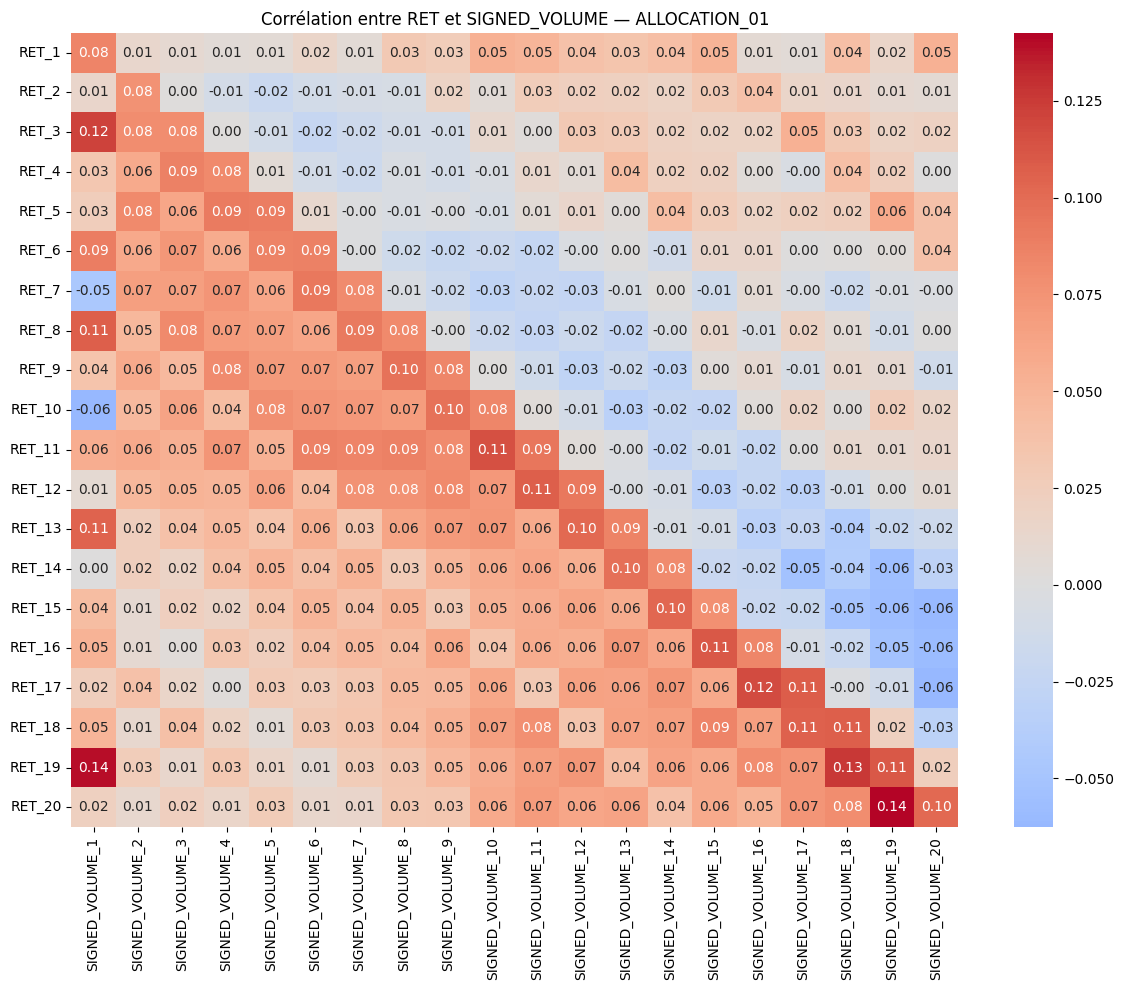

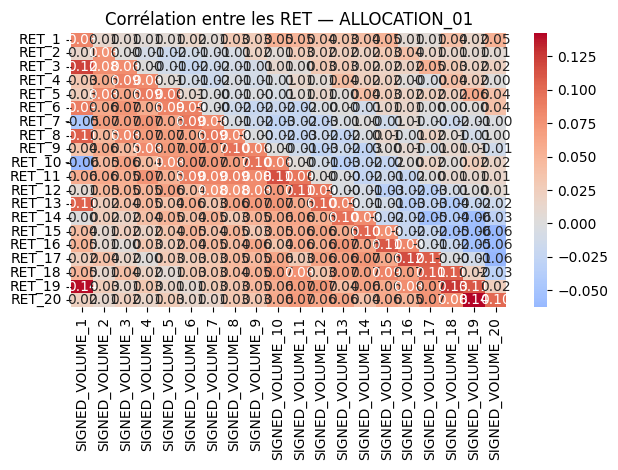

In [76]:
ret_cols = sorted(
    [c for c in X_train.columns if c.startswith("RET_") and c[4:].isdigit()],
    key=lambda c: int(c[4:])
)

allocation_01 = X_train.loc[
    X_train["ALLOCATION"] == "ALLOCATION_01", ret_cols
]

corr_matrix = allocation_01.corr()
display(corr_matrix)

ret_cols = sorted(
    [c for c in X.columns if c.startswith("RET_") and c[4:].isdigit()],
    key=lambda c: int(c[4:])
)
signed_volume_cols = sorted(
    [c for c in X.columns if c.startswith("SIGNED_VOLUME_")],
    key=lambda c: int(c.rsplit("_", 1)[-1])
)

if not signed_volume_cols:
    raise ValueError("Aucune colonne SIGNED_VOLUME_ trouvée.")

allocation_01 = X.loc[
    X["ALLOCATION"] == "ALLOCATION_01",
    ret_cols + signed_volume_cols
]

corr_matrix = allocation_01.corr().loc[ret_cols, signed_volume_cols]
display(corr_matrix)

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Corrélation entre RET et SIGNED_VOLUME — ALLOCATION_01")
plt.tight_layout()
plt.show()
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Corrélation entre les RET — ALLOCATION_01")
plt.tight_layout()
plt.show()


Train / Test split

In [51]:
# Trier les dates par leur numéro
dates = sorted(
    X["TS"].unique(),
    key=lambda ts: int(ts.split("_")[1])
)

# Utiliser un historique récent avant la période de validation
n_train_dates = 1000
n_valid_dates = 120

if n_train_dates <= 0 or n_valid_dates <= 0:
    raise ValueError("Les tailles d’entraînement et de validation doivent être positives.")
if len(dates) < n_train_dates + n_valid_dates:
    raise ValueError("Historique insuffisant pour les fenêtres demandées.")

train_dates = dates[-(n_train_dates + n_valid_dates):-n_valid_dates]
valid_dates = dates[-n_valid_dates:]

train_mask = X["TS"].isin(train_dates)
valid_mask = X["TS"].isin(valid_dates)

X_train = X.loc[train_mask].copy()
X_test = X.loc[valid_mask].copy()

Y_train = Y.loc[X_train.index].copy()
Y_train_sign = (Y_train['target']>0).astype(int)
Y_train_sign = pd.DataFrame(Y_train_sign)
Y_test = Y.loc[X_test.index].copy()

Retrieving useful features

In [52]:
# Sélection manuelle des variables pour LightGBM
features_lgbm = [
    'ALLOCATIONS_STD_PERF_20',
    'Ret1_Zscore',
    'ALLOCATIONS_STD_PERF_5',
    'STD_PERF_5',
    'ALLOCATIONS_AVERAGE_PERF_10',
    'Vol_Momentum_20',
    'ALLOCATION',
    'Vol_Ret_Confirm_1',
#    'STD_Perf_20',
    'Momentum_10',
    'Vol_Ratio_5_20'
]

# Ridge utilise uniquement les variables numériques de cette sélection.
features = [feature for feature in features_lgbm if feature != 'ALLOCATION']
features_lgbm


['ALLOCATIONS_STD_PERF_20',
 'Ret1_Zscore',
 'ALLOCATIONS_STD_PERF_5',
 'STD_PERF_5',
 'ALLOCATIONS_AVERAGE_PERF_10',
 'Vol_Momentum_20',
 'ALLOCATION',
 'Vol_Ret_Confirm_1',
 'Momentum_10',
 'Vol_Ratio_5_20']

In [53]:
y_test_vector = (Y_test['target']>0).astype(int)
y_test_vector

ROW_ID
501413    0
501414    0
501415    0
501416    0
501417    0
         ..
527068    0
527069    1
527070    1
527071    1
527072    1
Name: target, Length: 25660, dtype: int64

## Pouvoir prédictif de chaque variable seule

Un LightGBM univarié est entraîné pour chaque feature, avec les mêmes paramètres fixes, puis évalué sur la validation temporelle. Il peut apprendre une relation non monotone, sans interaction avec les autres variables. Les catégories natives et les valeurs manquantes sont prises en charge.

Le classement utilise l’AUC de validation : 0,5 correspond à un classement aléatoire et 1 à une séparation parfaite. L’accuracy utilise le seuil fixe de 0,5 et est comparée à une prédiction constante choisie sur l’entraînement. Ces scores dépendent du modèle univarié retenu ; ils ne mesurent pas seulement le meilleur seuil de séparation. Les features dérivées sont évaluées individuellement, même si leur calcul utilise plusieurs colonnes sources.

La validation ne sert ni à l’early stopping ni au réglage des paramètres. Si ce classement sert à sélectionner des features, il faudra une autre période réservée pour évaluer la sélection finale.


Accuracy de référence (classe majoritaire du train) : 52.21%


,auc_validation,accuracy_validation,gain_accuracy_vs_constante
variable,,,
ALLOCATIONS_STD_PERF_20,0.526065,0.519135,-0.002962
Ret1_Zscore,0.522878,0.522915,0.000818
ALLOCATIONS_STD_PERF_5,0.517023,0.520031,-0.002065
STD_PERF_5,0.514853,0.520265,-0.001832
ALLOCATIONS_AVERAGE_PERF_10,0.514638,0.519174,-0.002923
Vol_Momentum_20,0.514296,0.520499,-0.001598
ALLOCATION,0.510945,0.514809,-0.007288
Vol_Ret_Confirm_1,0.509429,0.520460,-0.001637
Momentum_10,0.506955,0.511691,-0.010405


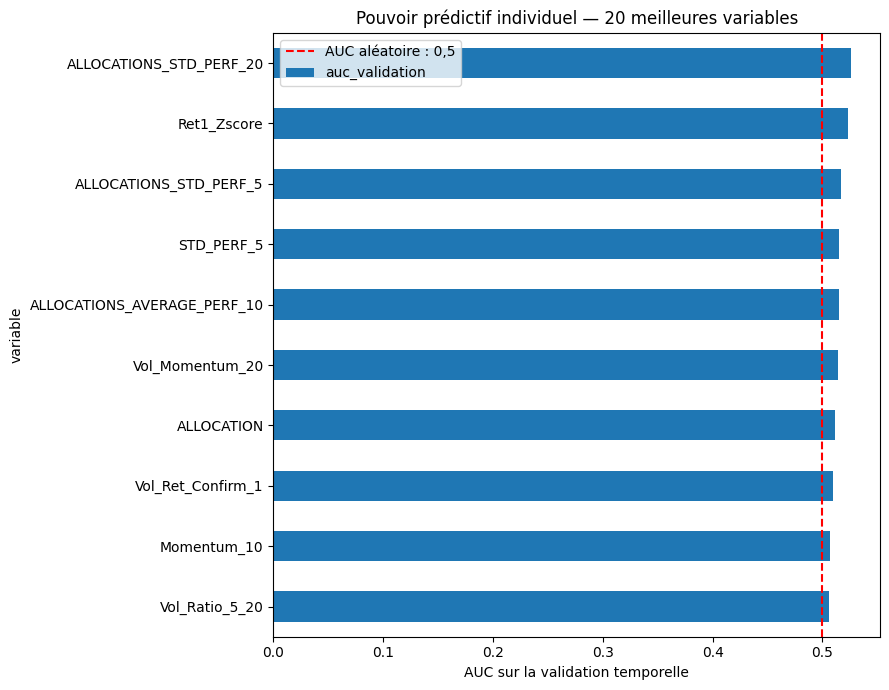

In [32]:
import lightgbm as lgbm
from sklearn.metrics import roc_auc_score, accuracy_score

univariate_y_train = (Y_train.loc[X_train.index, "target"] > 0).astype(int)
univariate_y_valid = (Y_test.loc[X_test.index, "target"] > 0).astype(int)
if univariate_y_train.nunique() < 2 or univariate_y_valid.nunique() < 2:
    raise ValueError("L’entraînement et la validation doivent contenir les deux classes.")

majority_class = int(univariate_y_train.mean() > 0.5)
baseline_accuracy = accuracy_score(
    univariate_y_valid, np.full(len(univariate_y_valid), majority_class)
)

# Paramètres identiques pour toutes les variables, sans réglage sur la validation.
univariate_params = {
    "objective": "binary",
    "verbosity": -1,
    "learning_rate": 0.05,
    "num_leaves": 7,
    "max_depth": 3,
    "min_data_in_leaf": 100,
    "seed": 42,
    "num_threads": 4,
    "deterministic": True,
    "force_col_wise": True,
}
univariate_results = []
for feature in features_lgbm:
    single_feature_model = lgbm.train(
        univariate_params,
        lgbm.Dataset(X_train[[feature]], label=univariate_y_train),
        num_boost_round=100,
    )
    single_feature_proba = single_feature_model.predict(
        X_test[[feature]], num_threads=4
    )
    feature_accuracy = accuracy_score(
        univariate_y_valid, (single_feature_proba > 0.5).astype(int)
    )
    univariate_results.append({
        "variable": feature,
        "auc_validation": roc_auc_score(univariate_y_valid, single_feature_proba),
        "accuracy_validation": feature_accuracy,
        "gain_accuracy_vs_constante": feature_accuracy - baseline_accuracy,
    })

univariate_scores = pd.DataFrame(univariate_results).set_index("variable").sort_values(
    "auc_validation", ascending=False
)
print(f"Accuracy de référence (classe majoritaire du train) : {baseline_accuracy:.2%}")
display(univariate_scores)

ax = univariate_scores.head(20).sort_values("auc_validation")["auc_validation"].plot.barh(
    figsize=(9, 7), title="Pouvoir prédictif individuel — 20 meilleures variables"
)
ax.axvline(0.5, color="red", linestyle="--", label="AUC aléatoire : 0,5")
ax.set_xlabel("AUC sur la validation temporelle")
ax.legend()
plt.tight_layout()
plt.show()


# Training

## Linear Model

In [54]:
from sklearn import linear_model
new_ridge = linear_model.Ridge(alpha=1)

new_ridge.fit(X_train[features].to_numpy(na_value=0),Y_train.to_numpy(na_value=0))

preds_ridge_df = pd.DataFrame(new_ridge.predict(X_test[features].fillna(0).to_numpy(na_value=0)),columns=['target'])

preds_ridge_vector = (preds_ridge_df>0).astype(int)

In [34]:
score = accuracy_score(y_test_vector, preds_ridge_vector)
print(f'Ridge Model Accuracy: {score}')

Ridge Model Accuracy: 0.5203819173811379


## LGBM

In [55]:
import lightgbm as lgbm

Model tuning

In [56]:
%load_ext autoreload
%autoreload 2
from utils import k_folds as k

# # 1. Recherche des meilleurs hyperparamètres (mode rapide ~5-10 min)
best_params, study = k.optimize_lgbm(
    X_train, Y_train_sign, features_lgbm,
    n_trials=32,
    num_boost_round=500,          # réduit (early stopping coupe avant)
    early_stopping_rounds=50,     # arrête si pas d'amélioration
    n_splits=6,                   
    subsample_frac=1,           
    num_threads=-1,               # tous les cœurs CPU
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Best trial: 6. Best value: 0.520926: 100%|██████████| 32/32 [02:52<00:00,  5.40s/it]


✅ Meilleure accuracy OOF : 52.09%
   Meilleurs paramètres   : {'learning_rate': 0.0123999678368461, 'max_depth': 3, 'num_leaves': 124, 'min_child_samples': 392, 'feature_fraction': 0.9636993649385135, 'bagging_fraction': 0.9368964102565893, 'lambda_l1': 0.09761125443110447, 'lambda_l2': 4.067908494359541}


Model training

In [67]:
from utils import k_folds as k
models, scores = k.run_lgbm(X_train, Y_train_sign, features_lgbm, best_params)

Fold 1 - Accuracy: 52.01% (best_iter=36)
Fold 2 - Accuracy: 51.82% (best_iter=72)
Fold 3 - Accuracy: 51.71% (best_iter=120)
Fold 4 - Accuracy: 51.46% (best_iter=54)
Fold 5 - Accuracy: 53.31% (best_iter=392)
Fold 6 - Accuracy: 52.24% (best_iter=156)
Accuracy: 52.09% [51.50 ; 52.69] (+- 0.60)


In [68]:
valid_proba = np.column_stack([
    model.predict(X_test[features_lgbm])
    for model in models
]).mean(axis=1)

score = accuracy_score(
    (Y_test["target"] > 0).astype(int),
    (valid_proba > 0.5).astype(int),
)

print(f"Accuracy sur les 120 dates réservées : {score:.2%}")

Accuracy sur les 120 dates réservées : 52.64%


Formatting and submission

In [ ]:
X_submission = pd.read_csv('data/X_Test.csv', index_col='ROW_ID')
data_handling.add_features(X_submission)

sample_submission = pd.read_csv('data/sample_submission.csv', index_col='ROW_ID')

preds_all = np.column_stack([
    m.predict(X_submission[features_lgbm], num_threads=-1)
    for m in models
])

preds_mean = preds_all.mean(axis=1)

preds_binary = (preds_mean > 0.5).astype(int)

submission = pd.DataFrame(
    preds_binary,
    index=sample_submission.index,
    columns=['target']
)
submission.to_csv('data/submission.csv')
print(f"Submission saved: {submission.shape[0]} rows")
print(f"Distribution: {preds_binary.mean()*100:.1f}% de 1, {(1-preds_binary.mean())*100:.1f}% de 0")
submission.head()